In [ ]:
!pip -q install tensorflow scikit-learn seaborn

In [ ]:
!pip -q install kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "birdy654/cifake-real-and-ai-generated-synthetic-images"
)

print("Dataset downloaded to:")
print(dataset_path)

100%|██████████| 105M/105M [00:00<00:00, 243MB/s] 

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3


In [ ]:
import os

for root, dirs, files in os.walk(dataset_path):
    if files:
        print(root, "->", len(files), "files")

/root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/train/REAL -> 50000 files
/root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/train/FAKE -> 50000 files
/root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/test/REAL -> 10000 files
/root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/test/FAKE -> 10000 files


In [ ]:
train_dir = os.path.join(dataset_path, "train")
test_dir  = os.path.join(dataset_path, "test")

print("TRAIN:", train_dir)
print("TEST :", test_dir)

TRAIN: /root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/train
TEST : /root/.cache/kagglehub/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images/versions/3/test


In [ ]:
print("Train classes:", os.listdir(train_dir))
print("Test classes :", os.listdir(test_dir))

print("FAKE train:", len(os.listdir(os.path.join(train_dir, "FAKE"))))
print("REAL train:", len(os.listdir(os.path.join(train_dir, "REAL"))))

print("FAKE test:", len(os.listdir(os.path.join(test_dir, "FAKE"))))
print("REAL test:", len(os.listdir(os.path.join(test_dir, "REAL"))))

Train classes: ['REAL', 'FAKE']
Test classes : ['REAL', 'FAKE']
FAKE train: 50000
REAL train: 50000
FAKE test: 10000
REAL test: 10000


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 64
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

CLASS_NAMES = train_ds.class_names

print("Classes:", CLASS_NAMES)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Classes: ['FAKE', 'REAL']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import layers

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("Base model loaded.")


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model loaded.


In [ ]:
from tensorflow.keras import Model

inputs = layers.Input(shape=(224, 224, 3))

x = augmentation(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.30)(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.20)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        "/content/AI_Media_Guard_Best.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


In [ ]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 275s 167ms/step - accuracy: 0.8374 - loss: 0.3653 - val_accuracy: 0.9011 - val_loss: 0.2449 - learning_rate: 1.0000e-04
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 167ms/step - accuracy: 0.8792 - loss: 0.2876 - val_accuracy: 0.9119 - val_loss: 0.2222 - learning_rate: 1.0000e-04
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 167ms/step - accuracy: 0.8887 - loss: 0.2659 - val_accuracy: 0.9185 - val_loss: 0.2072 - learning_rate: 1.0000e-04
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 260s 167ms/step - accuracy: 0.8954 - loss: 0.2514 - val_accuracy: 0.9241 - val_loss: 0.1943 - learning_rate: 1.0000e-04
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 260s 167ms/step - accuracy: 0.9020 - loss: 0.2376 - val_accuracy: 0.9281 - val_loss: 0.1864 - learning_rate: 1.0000e-04
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 262s 167ms/step - accuracy: 0.9059 - loss: 0.2280 - val_accuracy: 0.9319 - val_loss: 0.1772 - learning_rate: 1.0000e-04
Epoch 7/15
1563/1563 ━━━━━━━

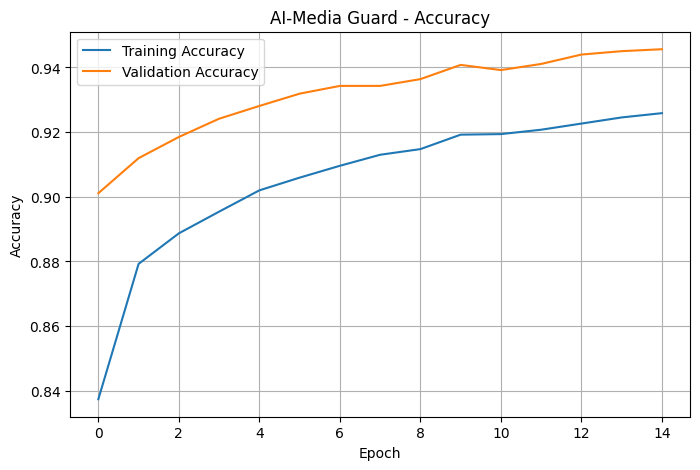

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("AI-Media Guard - Accuracy")
plt.legend()
plt.grid(True)

plt.show()

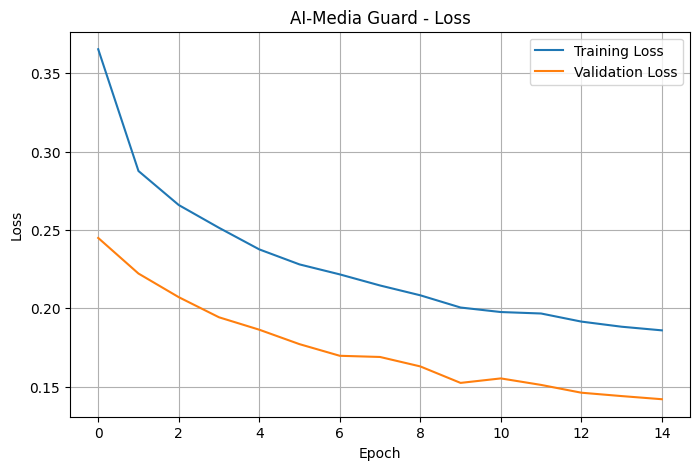

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AI-Media Guard - Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("--------------------------------")
print("TEST ACCURACY:", round(test_accuracy * 100, 2), "%")
print("TEST LOSS:", round(test_loss, 4))
print("--------------------------------")

313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 129ms/step - accuracy: 0.9456 - loss: 0.1421
--------------------------------
TEST ACCURACY: 94.56 %
TEST LOSS: 0.1421
--------------------------------


              precision    recall  f1-score   support

        FAKE       0.95      0.94      0.95     10000
        REAL       0.94      0.95      0.95     10000

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



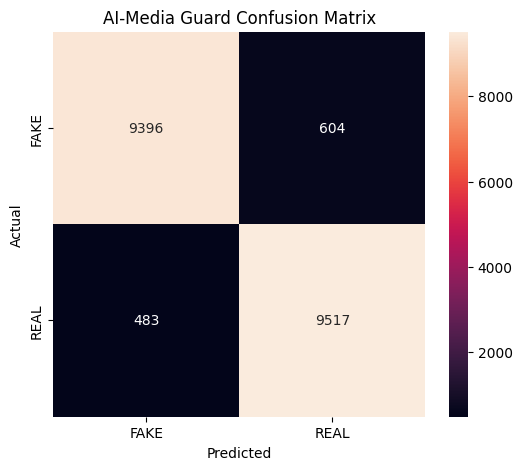

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_pred.extend((predictions.flatten() >= 0.5).astype(int))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("AI-Media Guard Confusion Matrix")

plt.show()

In [ ]:
model.save("/content/AI_Media_Guard_Image_Model.keras")

print("✅ Model saved successfully!")

✅ Model saved successfully!


In [ ]:
from google.colab import files

files.download(
    "/content/AI_Media_Guard_Image_Model.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "/content/AI_Media_Guard_Best.keras"
)

print("✅ Best model loaded")

✅ Best model loaded


In [ ]:
base_model.trainable = True

# Sirf last 30 layers trainable
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable layers:
block6d_expand_bn
block6d_expand_activation
block6d_dwconv
block6d_bn
block6d_activation
block6d_se_squeeze
block6d_se_reshape
block6d_se_reduce
block6d_se_expand
block6d_se_excite
block6d_project_conv
block6d_project_bn
block6d_drop
block6d_add
block7a_expand_conv
block7a_expand_bn
block7a_expand_activation
block7a_dwconv
block7a_bn
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
block7a_project_bn
top_conv
top_bn
top_activation


In [ ]:
fine_history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 272s 167ms/step - accuracy: 0.9272 - loss: 0.1811 - val_accuracy: 0.9453 - val_loss: 0.1412 - learning_rate: 1.0000e-05
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 167ms/step - accuracy: 0.9275 - loss: 0.1817 - val_accuracy: 0.9449 - val_loss: 0.1408 - learning_rate: 1.0000e-05
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 167ms/step - accuracy: 0.9277 - loss: 0.1799 - val_accuracy: 0.9450 - val_loss: 0.1405 - learning_rate: 1.0000e-05
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 261s 167ms/step - accuracy: 0.9288 - loss: 0.1796 - val_accuracy: 0.9452 - val_loss: 0.1406 - learning_rate: 1.0000e-05
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 262s 168ms/step - accuracy: 0.9285 - loss: 0.1791 - val_accuracy: 0.9457 - val_loss: 0.1397 - learning_rate: 1.0000e-05
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 262s 168ms/step - accuracy: 0.9279 - loss: 0.1806 - val_accuracy: 0.9459 - val_loss: 0.1393 - learning_rate: 1.0000e-05
Epoch 7/10
1563/1563 ━━━━━━━

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n==============================")
print("FINAL TEST ACCURACY:",
      round(test_accuracy * 100, 2), "%")
print("FINAL TEST LOSS:",
      round(test_loss, 4))
print("==============================")

313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 134ms/step - accuracy: 0.9459 - loss: 0.1389

FINAL TEST ACCURACY: 94.59 %
FINAL TEST LOSS: 0.1389


In [ ]:
model.save(
    "/content/AI_Media_Guard_Image_Final.keras"
)

print("✅ Final model saved!")

✅ Final model saved!


In [36]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded:", image_path)

Saving luqman pic.jpeg to luqman pic.jpeg
Uploaded: luqman pic.jpeg


In [41]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

def predict_image(image_path):

    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)

    img_array = np.expand_dims(
        img_array,
        axis=0
    )

    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    classes = CLASS_NAMES # Changed from train_ds.class_names to CLASS_NAMES

    if prediction >= 0.5:
        predicted_class = classes[1]
        confidence = prediction
    else:
        predicted_class = classes[0]
        confidence = 1 - prediction

    print("\n==============================")
    print("AI-MEDIA GUARD RESULT")
    print("==============================")

    print("Prediction :", predicted_class)
    print("Confidence :", round(confidence * 100, 2), "%")

    print("==============================")

    return predicted_class, confidence

In [42]:
!pip install -q kaggle

In [43]:
!kaggle datasets download -d dhruvvirani/deepfake-videos

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [44]:
!unzip -q deepfake-videos.zip

unzip:  cannot find or open deepfake-videos.zip, deepfake-videos.zip.zip or deepfake-videos.zip.ZIP.


In [45]:
!kaggle competitions download -c deepfake-detection

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [47]:
import os

for root, dirs, files in os.walk("."):
    videos = [f for f in files if f.endswith(".mp4")]
    if videos:
        print(root, "→", len(videos), "videos")

. → 1 videos


In [48]:
import glob

videos = glob.glob("**/*.mp4", recursive=True)

print("Total videos:", len(videos))
print("\nFirst 10 videos:")
for v in videos[:10]:
    print(v)

Total videos: 1

First 10 videos:
15428477_1920_1080_30fps.mp4


In [49]:
CLASS_NAMES = {
    "real": 0,
    "fake": 1
}

print(CLASS_NAMES)

{'real': 0, 'fake': 1}


In [50]:
import cv2

video_path = videos[0]

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frames / fps if fps else 0

print("Video:", video_path)
print("FPS:", fps)
print("Frames:", frames)
print("Duration:", round(duration, 2), "seconds")

cap.release()

Video: 15428477_1920_1080_30fps.mp4
FPS: 30.0
Frames: 300
Duration: 10.0 seconds


In [51]:
import cv2
import os

def extract_frames(video_path, num_frames=10):
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = [
        int(i * total_frames / num_frames)
        for i in range(num_frames)
    ]

    frames = []

    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

    cap.release()

    return frames

In [ ]:
frames = extract_frames(videos[0], num_frames=10)

print("Extracted frames:", len(frames))
print("Frame shape:", frames[0].shape if frames else "No frame")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

for i, frame in enumerate(frames):
    plt.subplot(2, 5, i + 1)
    plt.imshow(frame)
    plt.axis("off")
    plt.title(f"Frame {i+1}")

plt.show()